# Car Price Prediction with Machine Learning
**Author:** Syed Aon Muhammad Kazmi  
**Track:** Data Science | OASIS INFOBYTE

## Objective and data
Data: used-car listings from CarDekho, public mirror https://github.com/chandanverma07/DataSets/blob/master/CAR%20DETAILS%20FROM%20CAR%20DEKHO.csv. Prices are treated as INR; km_driven is distance travelled, not fuel efficiency. Historical listings are not current valuations.

Reproducible seed: 42. Model selection uses cross-validation on training data; the held-out test set is evaluated once per candidate for reporting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, classification_report, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, r2_score)
sns.set_theme(style='whitegrid', palette='colorblind')
SEED = 42
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)
def save(name):
    plt.savefig(OUT / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
def inspect(df):
    print('Shape:', df.shape)
    display(df.head(), df.dtypes.to_frame('dtype'), df.isna().sum().to_frame('missing'), df.describe(include='all'))


In [2]:
df=pd.read_csv('data/cars.csv');inspect(df)
print('Duplicate rows removed:',df.duplicated().sum());df=df.drop_duplicates().copy()
for col in df.select_dtypes('object'): df[col]=df[col].str.strip().str.lower()
for col in ['year','selling_price','km_driven']: df[col]=pd.to_numeric(df[col],errors='coerce')
df=df.dropna(subset=['selling_price','year']);df=df[(df.selling_price>0)&(df.km_driven>=0)].copy()
REFERENCE_YEAR=int(df.year.max())
df['car_age']=REFERENCE_YEAR-df.year
df['brand']=df['name'].str.split().str[0]
print('Fixed dataset reference year:',REFERENCE_YEAR,'Clean shape:',df.shape)

Shape: (4340, 8)
Duplicate rows removed: 763
Fixed dataset reference year: 2020 Clean shape: (3577, 10)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


,dtype
name,object
year,int64
selling_price,int64
km_driven,int64
fuel,object
seller_type,object
transmission,object
owner,object


,missing
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
count,4340,4340.000000,4.340000e+03,4340.000000,4340,4340,4340,4340
unique,1491,NaN,NaN,NaN,5,3,2,5
top,Maruti Swift Dzire VDI,NaN,NaN,NaN,Diesel,Individual,Manual,First Owner
freq,69,NaN,NaN,NaN,2153,3244,3892,2832
mean,NaN,2013.090783,5.041273e+05,66215.777419,NaN,NaN,NaN,NaN
std,NaN,4.215344,5.785487e+05,46644.102194,NaN,NaN,NaN,NaN
min,NaN,1992.000000,2.000000e+04,1.000000,NaN,NaN,NaN,NaN
25%,NaN,2011.000000,2.087498e+05,35000.000000,NaN,NaN,NaN,NaN
50%,NaN,2014.000000,3.500000e+05,60000.000000,NaN,NaN,NaN,NaN
75%,NaN,2016.000000,6.000000e+05,90000.000000,NaN,NaN,NaN,NaN


## Cleaning and feature engineering
A fixed reference year based on the dataset makes age reproducible. It describes age at that reference year, not age today. Exact duplicates are removed before splitting. Category normalisation avoids Petrol/petrol becoming separate levels. Missing feature values are imputed inside the modelling pipeline.

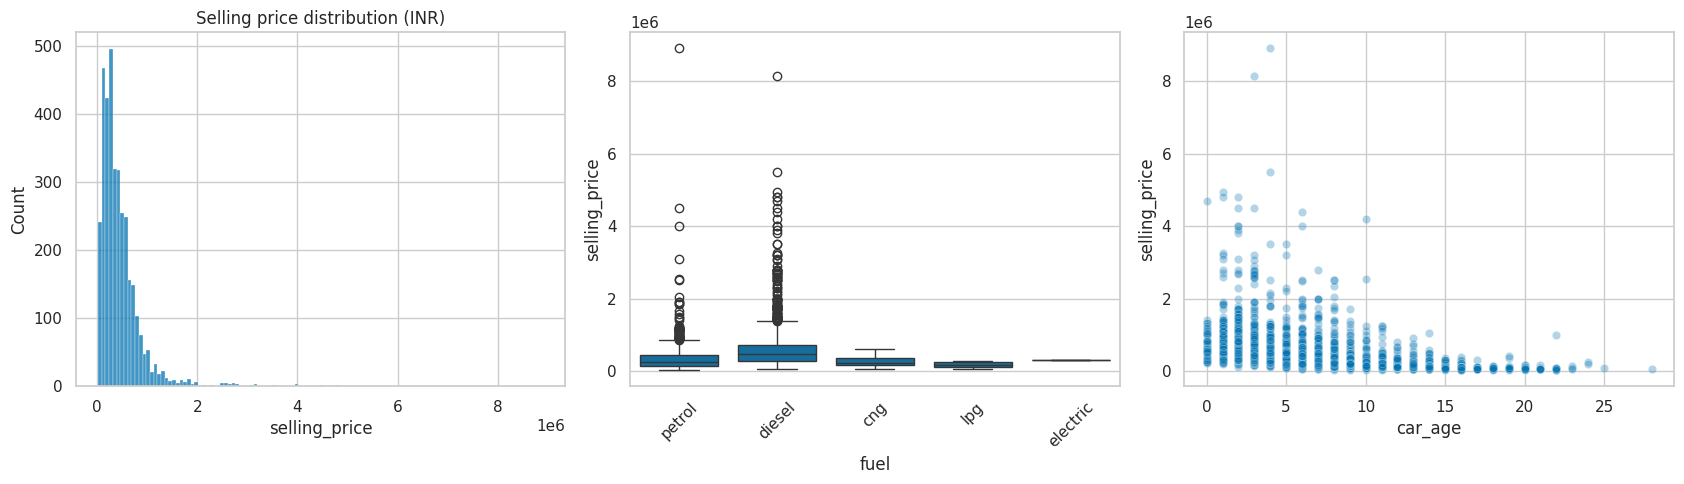

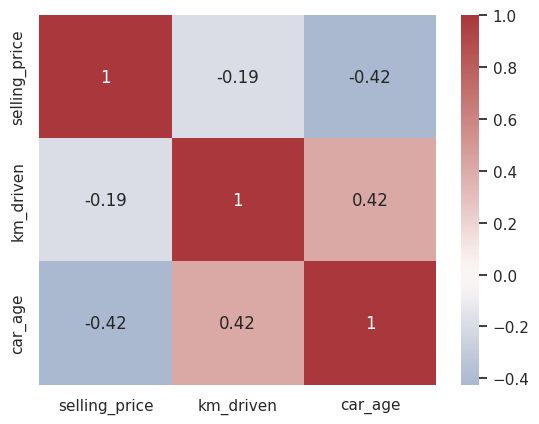

In [3]:
fig,axes=plt.subplots(1,3,figsize=(17,5))
sns.histplot(df.selling_price,ax=axes[0]);axes[0].set_title('Selling price distribution (INR)')
sns.boxplot(data=df,x='fuel',y='selling_price',ax=axes[1]);axes[1].tick_params(axis='x',rotation=45)
sns.scatterplot(data=df,x='car_age',y='selling_price',ax=axes[2],alpha=.3)
plt.tight_layout();save('eda')
sns.heatmap(df[['selling_price','km_driven','car_age']].corr(),annot=True,cmap='vlag',center=0);save('correlation')

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
features=['car_age','km_driven','brand','fuel','seller_type','transmission','owner']
X=df[features];y=df.selling_price
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=SEED)
num=['car_age','km_driven'];cat=[c for c in features if c not in num]
pre=ColumnTransformer([('num',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),num),('cat',make_pipeline(SimpleImputer(strategy='most_frequent'),OneHotEncoder(handle_unknown='ignore',sparse_output=False)),cat)])
models={'Linear Regression':make_pipeline(pre,LinearRegression()),'Random Forest':make_pipeline(pre,RandomForestRegressor(n_estimators=200,min_samples_leaf=2,random_state=SEED,n_jobs=1))}

Selected: Linear Regression by lowest training CV RMSE.
Example predicted INR: 527598


,Model,CV RMSE,MAE,RMSE,R2
0,Linear Regression,299460.148752,179641.768082,384722.698406,0.540527
1,Random Forest,300078.819621,156381.187819,358751.267268,0.600468


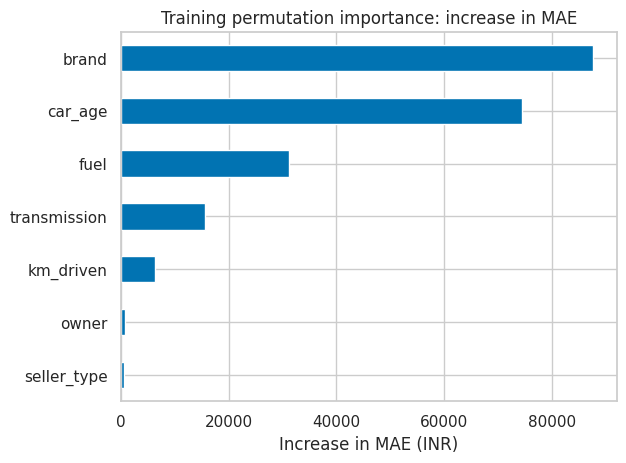

In [5]:
cv=KFold(5,shuffle=True,random_state=SEED);rows=[]
for name,model in models.items():
    cv_rmse=-cross_val_score(model,X_train,y_train,scoring='neg_root_mean_squared_error',cv=cv).mean()
    model.fit(X_train,y_train);pred=model.predict(X_test)
    rows.append({'Model':name,'CV RMSE':cv_rmse,'MAE':mean_absolute_error(y_test,pred),'RMSE':np.sqrt(mean_squared_error(y_test,pred)),'R2':r2_score(y_test,pred)})
results=pd.DataFrame(rows).sort_values('CV RMSE');display(results);results.to_csv(OUT/'metrics.csv',index=False)
best_name=results.iloc[0]['Model'];best=models[best_name];print('Selected:',best_name,'by lowest training CV RMSE.')
from sklearn.inspection import permutation_importance
# Training-only importances keep the test set out of feature interpretation.
importance=permutation_importance(best,X_train,y_train,n_repeats=5,random_state=SEED,scoring='neg_mean_absolute_error')
pd.Series(importance.importances_mean,index=features).sort_values().plot.barh(title='Training permutation importance: increase in MAE');plt.xlabel('Increase in MAE (INR)');save('feature_importance')
print('Example predicted INR:',round(best.predict(X_test.iloc[[0]])[0]))

## Limitations
Listings may share models, sellers or vehicles; without unique vehicle identifiers we cannot guarantee independent groups. Random splits measure same-source generalisation, not future market performance. Large RMSE relative to MAE suggests expensive-car errors. Training permutation importance is descriptive and may be optimistic; a larger validation dataset is needed before deployment.

## Results from the verified run
Linear Regression narrowly wins mean training CV RMSE (299,460 INR versus 300,079 INR). Random Forest achieves lower held-out RMSE (358,751 versus 384,723 INR) and MAE, but we retain the predeclared training-CV choice rather than select retrospectively on test results. The close CV means and heavy price tail make the ranking uncertain; more folds/seeds and validation data would be needed for a firm winner.